# Visualizing fire scars through false color

**Author:** Monique A. Hernandez

**Date:** November 21, 2026

[GitHub Repository](https://github.com/moniqueallyson/eds220-hwk4)


## 1. About Section

### Purpose

The purpose of this notebook is to explore the environmental impact caused by the fires in Palisades and Eaton that occurred almost simultaneously in Los Angeles County at the start of January 2025. The final output for this notebook is a false color image utilizing remote sensing techniques after data exploration and cleaning to visualize the affected areas through the use of the fire perimeters dataset. Data collected by satellites are useful when assigning infrared to visible light to create images that highlight vegetation health, burn severity, and extent of fire scars, which can then help researchers plan restoration strategies and identify high-risk areas for future planning.

### Highlights


- Restoration of CRS through exploratory retrieval using correct variable, `spatial_ref.crs_wkt`.

- For correct true color imagery using RGB (visible light), then filling in `NaN` values with 0 for bands.

- False color imagery using short-wave infrared, near-infrared, and red.

- Creating a false color image and depicting the fire perimeters using boundaries to represent Palisades and Eaton fires.


### Dataset description

For this notebook, there are two major datasets:

1. Landsat 8 satellite

- The first data set, collected by Landsat 8 satellite, is used for its collection of bands (red, green, near-infrared and short-wave infrared), which is from the Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data.
- The data was retrieved from [Microsoft Planetary Computer data catalog](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2), though the data was already given by the instructor and clipped to the surrounding areas for the fire perimeters of both Palisades and Eaton, found in a Google Drive.

2. Palisades and Eaton Fire Perimeter

- The second dataset includes both the fire perimeters for Palisades and Eaton which were retrieved from [ArcGIS](https://hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about).
- For this analysis, we will be using the geometry for the boundary information needed for both fires.


### References

County of Los Angeles. (2025). *Palisades and Eaton dissolved fire perimeters* [Dataset]. ArcGIS Hub. https://hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c 

NASA. (2025, December 8). *Why is that forest red and that cloud blue? How to interpret a false-color satellite image*. https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/

U.S. Geological Survey. (2025). Landsat Collection 2 Level-2 [Dataset]. Microsoft Planetary Computer. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2 

In [144]:
# Import libraries

import pandas as pd
import os
import numpy as np
import geopandas as gpd
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt

## 2. Fire Perimeter Data Exploration

In [145]:
# Import data

fp = os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp)

fp = os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp)


In [146]:
# Explore CRS for both Palisades and Eaton
print(f"Palisades' CRS: {palisades.crs}")
print(f"Eaton's CRS: {eaton.crs}")

Palisades' CRS: EPSG:4269
Eaton's CRS: EPSG:4269


In [147]:
# Explore geographic or projected for Eaton 
print('Is Eaton geographic?: ', eaton.crs.is_geographic)
print('Is Eaton projected?: ', eaton.crs.is_projected)

Is Eaton geographic?:  True
Is Eaton projected?:  False


In [148]:
# Explore geographic or projected for Palisades 
print('Is Palisades geographic?: ', palisades.crs.is_geographic)
print('Is Palisades projected?: ', palisades.crs.is_projected)

Is Palisades geographic?:  True
Is Palisades projected?:  False


### Exploration summary

The CRS for both Palisades and Eaton is EPSG:4269 and for both they are geographic. They will need to be reprojected in order to match the CRS of Landsat to create the maps.

## 3. NetCDF data import and exploration

In [149]:
# Load Landsat 8 data

landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

### Summary of Landsat exploration

Landsat has the following variables: red, green, blue, nir08, swir22, and spatial_ref.

There are five spectral bands:
1. Visible light: red, green, and blue.
2. Near-infrared, nir08, discerns land-water boundaries that are not obvious in visible light and shows vegetation health due to the strong reflection which is the key point here.
3. Swir22 is a short-wave infrared band that helps scientists estimate water presence in plants and soil which is helpful for mapping fire damage as more water means darker images.

 The dimensions are 1418 x 2742. 

 The coordinates show y, x, and time.

### Further readings

Readings for color images and Landsat imagery:

[NASA Earth Observatory - Why is that Forest Red and that Cloud Blue? How to Interpret a False-Color Satellite Image](https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/)

[What are the band designations for the Landsat satellites?](https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites)

[Common Landsat Band Combinations](https://www.usgs.gov/media/images/common-landsat-band-combinations)

## 4. Restoring geospatial information

In [150]:
# Find CRS for landsat
print(landsat.rio.crs)

None


### Is this a geospatial object?

No.

After printing `landsat.rio.crs`, there was a `None` output, which means Python does not see this as a geospatial object. Recover geospatial information by using `rio.write_crs()` after retrieving from `spatial_ref.crs_wkt`.

In [151]:
# Print CRS of landsat from variable spatial_ref
print(landsat.spatial_ref.crs_wkt)
landsat_crs = landsat.spatial_ref.crs_wkt

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [152]:
# Recover CRS
landsat = landsat.rio.write_crs(landsat_crs)

In [153]:
# Check again for CRS
print(landsat.rio.crs)

EPSG:32611


## 5. True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


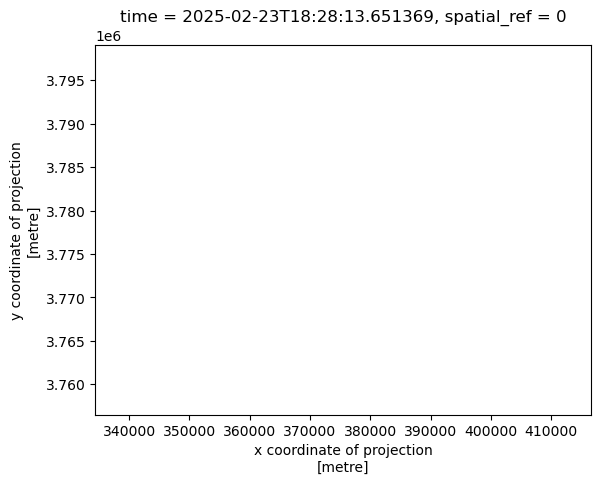

In [154]:
# Select RGB and add no adjustments
landsat[['red', 'green', 'blue']].to_array().plot.imshow()

Text(0.5, 1.0, 'True Color Image Palisades and Eaton Fire Scars')

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


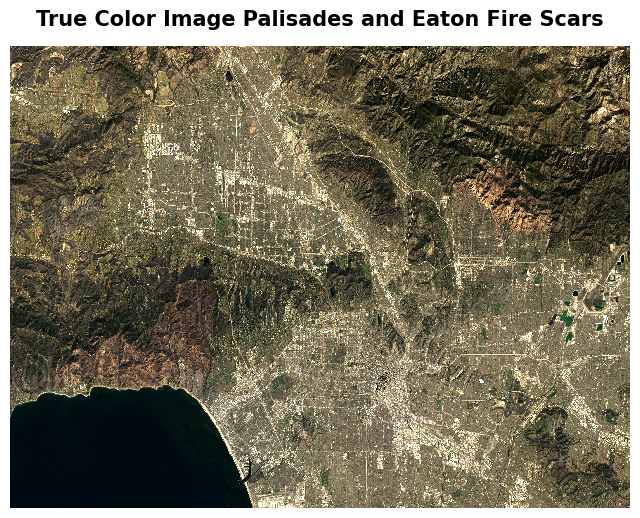

In [155]:
# Select RGB to create image and adjust scale
fig, ax = plt.subplots(figsize=(8, 6))
ax.axis('off')

landsat[['red', 'green', 'blue']].to_array().plot.imshow(robust=True)

ax.set_title('True Color Image Palisades and Eaton Fire Scars', 
             fontsize=15, 
             weight='bold', 
             pad=15
             )


In [156]:
# Identify NaN values
bands = ['red', 'green', 'blue', 'nir08', 'swir22']

for band in bands:
    count_nan = np.isnan(landsat[band]).sum().values
    print(f"{band} has {count_nan} NaN")

red has 0 NaN
green has 1 NaN
blue has 109 NaN
nir08 has 0 NaN
swir22 has 0 NaN


In [157]:
# Replace NaN values in Landsat with 0
landsat = landsat.fillna(0)

Text(0.5, 1.0, 'True Color Image Palisades and Eaton Fire Scars')

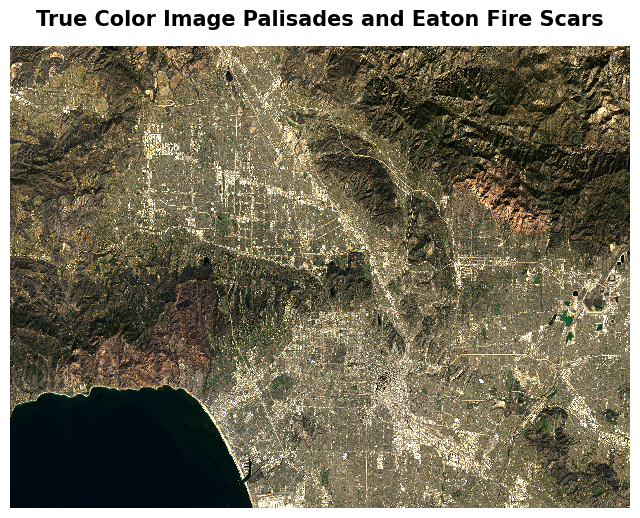

In [158]:
# Recreate image with no warnings
fig, ax = plt.subplots(figsize=(8, 6))
ax.axis('off')

landsat[['red', 'green', 'blue']].to_array().plot.imshow(ax=ax, robust=True)

ax.set_title('True Color Image Palisades and Eaton Fire Scars', 
             fontsize=15, 
             weight='bold', 
             pad=15
             )

### Summary for true color images

A few adjustments were needed before the final true color image of the burned areas for Palisades and Eaton was created due to two warnings which are listed here:

1. **Clipping Warning:** "Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers)." This was addressed by using `robust=True`, which adjusts the scale used for plotting the bands to get a visible image as clouds were most likely the culprit for the bright pixels.


2. "RuntimeWarning: invalid value encountered in cast xx = (xx * 255).astype(np.uint8)" After accounting for `NaN` resolved the warning since those values were missing and incapable of being converted into integers when mapped, which came from the bands, `green` and `blue`.



## 6. False color image

Text(0.5, 1.0, 'False Color Image Palisades and Eaton Fire Scars')

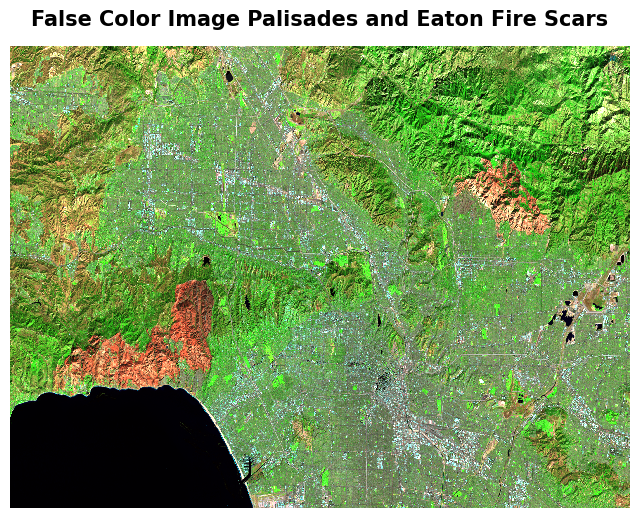

In [159]:
# Create false color image by plotting swir22, nir08, and red in order
fig, ax = plt.subplots(figsize=(8, 6))
ax.axis('off')

landsat[['swir22', 'nir08', 'red']].to_array().plot.imshow(ax=ax, robust=True)

ax.set_title('False Color Image Palisades and Eaton Fire Scars', 
             fontsize=15, 
             weight='bold', 
             pad=15
             )

## 7. Map

In [160]:
# Reproject perimeters to match landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# Check CRS match with assert
assert eaton.crs == landsat.rio.crs
assert palisades.crs == landsat.rio.crs

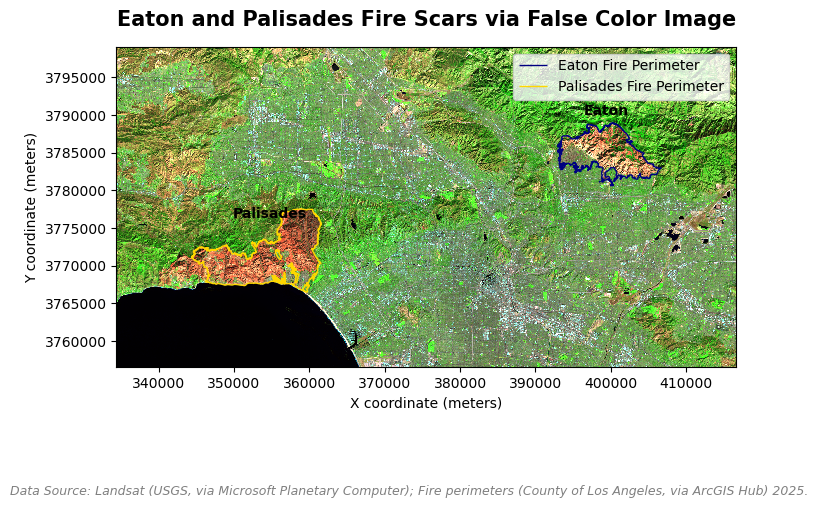

In [161]:
# False Color Map
fig, ax = plt.subplots(figsize=(8, 6))

# Plot false color image
landsat[['swir22', 'nir08', 'red']].to_array().plot.imshow(ax=ax, robust=True)

# Plot fire perimeter polygons on top of the image
eaton.boundary.plot(ax=ax, color="navy", linewidth=1, label="Eaton Fire Perimeter")
palisades.boundary.plot(ax=ax, color="gold", linewidth=1, label="Palisades Fire Perimeter")

# Add fire names as text annotations
for fire, name in [(eaton, 'Eaton'), (palisades, 'Palisades')]:
    center = fire.geometry.centroid.iloc[0]
    ax.text(center.x, center.y + 5000, name, fontsize=10, ha='center', weight='bold')

# Add labels
ax.set_title('Eaton and Palisades Fire Scars via False Color Image', 
             fontsize=15, 
             weight='bold', 
             pad=15
             )
plt.legend()
ax.set_xlabel('X coordinate (meters)')
ax.set_ylabel('Y coordinate (meters)')
fig.text(
    0.99,
    0.01,
    "Data Source: Landsat (USGS, via Microsoft Planetary Computer); "
         "Fire perimeters (County of Los Angeles, via ArcGIS Hub) 2025.",
    ha="right",
    va="bottom",
    fontsize=9,
    color="gray",
    style="italic",
)

ax.ticklabel_format(style='plain', useOffset=False)

plt.show()

### Summary for false color image

False color image shows the affected areas, in reddish-brown, for both Palisades and Eaton from the fires in January 2025. 

The false color image is created by using short-wave infrared (swir22) and near-infrared (nir08) as well as red bands, in that order. This highlights the affected areas by differentiating the burned areas (red-brown) and vegetation (green). The short-wave infrared shows bodies of water as darkest since it absorbs it, while the near-infrared shows the vegetation health as green since it reflects NIR strongly. The important aspect in these bands is that newly burned land reflects SWIR bands strongly which is how the burned areas can be seen visibly. This is all compiled to make it easier to differentiate than it is done through visible light due to the difference in band usage from the Landsat collection.

The Landsat collected the data on February 23, 2025, which was a few weeks after the fires occurred in both locations.